# Validación por bloques mensuales con origen móvil

En los cuadernos por unidad elegimos los modelos con la validación (los dos meses anteriores a la prueba) y los
evaluamos una sola vez en la prueba (los dos meses anteriores al corte del modelado). Cuatro meses de una o dos
estaciones son una muestra corta para concluir sobre toda la flota, así que en este cuaderno evaluamos cada unidad en
**todos los meses** con datos, de noviembre de 2025 hasta el corte del modelado, como se usaría en operación. Los días
posteriores al corte se pronostican igual, pero los resumimos aparte. La tabla resume el diseño, que sigue la
evaluación con origen móvil de Tashman (2000).

| Elemento | Decisión | Justificación |
|---|---|---|
| Bloques | Meses calendario, de noviembre de 2025 (o del primer mes del régimen vigente con al menos 14 días de entrenamiento) al último mes antes del corte | Cubren la temporada seca (diciembre a marzo), las lluviosas y las fases de La Niña débil y El Niño |
| Reajuste | Coeficientes e hiperparámetros reestimados cada trimestre (1 de noviembre, febrero, mayo y agosto), con todos los datos observados antes de esa fecha | El experimento de reentrenamiento de los cuadernos mostró que reestimar cada 7 o 30 días no cambia el error, el trimestre reparte el costo y el último coincide con el ajuste final de la prueba |
| Pronóstico | Día siguiente horario, emitido al final de cada día con los coeficientes vigentes | Es la operación diaria |
| Modelos | Persistencia, persistencia inteligente, climatología, CLIPER, SARIMA, SARIMAX E2-MOS, SARIMAX E2-PP, ensamble de aprendizaje automático E2 (y su mejor modelo individual) y MLP | Son los de los cuadernos sin la LSTM, cuyo costo e inestabilidad ya están documentados |
| Especificación | El orden del SARIMA, las variables y los componentes del ensamble son los de cada cuaderno, y los hiperparámetros se vuelven a buscar en cada reajuste | Los coeficientes e hiperparámetros solo ven el pasado de cada bloque |
| Desarrollo y confirmación | Bloques de noviembre de 2025 al fin de la validación para elegir, y la prueba y los días posteriores al corte (en vivo) para confirmar | La prueba sigue sin intervenir en la elección |
| Significancia | Pérdidas cuadráticas sumadas por día, conjunto de modelos equivalentes al mejor (Hansen et al., 2011) y Diebold-Mariano diario con corrección de Holm entre unidades | Controla las comparaciones múltiples |

Hay una consideración que declaramos. La especificación de cada unidad (variables, orden del SARIMA y componentes del
ensamble) se fijó con su entrenamiento, que termina donde empieza la validación, y por eso en los bloques anteriores
hay una pequeña ventaja de información sobre la especificación, aunque no sobre los coeficientes ni los
hiperparámetros, que siempre se estiman con el pasado del bloque. El aprendizaje automático se marca como indicativo en
los reajustes con menos de 60 días de entrenamiento.

In [1]:
PARTE = ""                     # "1/2" o "2/2": reparte las unidades entre dos procesos; "" = todas
SOLO_RESUMEN = False           # True: no ajusta; resume las predicciones ya guardadas
REHACER = False                # True: vuelve a ajustar aunque existan las predicciones de la unidad
RAPIDO = False                 # True: prueba rápida (una unidad, búsquedas y épocas mínimas)
GUARDAR_FIGURAS = True
SUF = ""                       # "_rapido": usa las entradas de las ejecuciones rápidas de prueba

In [2]:
# Parameters
PARTE = "1/2"


In [3]:
import os, sys, json, time, warnings
from pathlib import Path
if not Path("tfm").is_dir() and Path("../tfm").is_dir():
    os.chdir("..")     # copia ejecutada abierta desde notebooks/ejecutados: se trabaja desde notebooks/
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown as MarkdownIPython
def Markdown(texto):                  # cifras con coma decimal, como en el documento y las figuras
    return MarkdownIPython(gr.texto_es(texto))
def miles(n):                         # separador de miles con espacio: 12 345 (la coma sería decimal)
    return f"{int(n):,}".replace(",", " ")
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.multitest import multipletests

from tfm import config, graficos as gr, resultados as res, metricas as met, tiempos
from tfm.modelos import ml, redes, sarima, referencias as refs

tiempos.activar("BLOQUES" + (PARTE.replace("/", "de") if PARTE else ""))
config.fijar_semilla()
gr.estilo()
pd.set_option("display.max_columns", 40, "display.width", 200)
if RAPIDO:
    GUARDAR_FIGURAS = False
    res.registrar = lambda *a, **k: None
PREF = "bloques_"
# Reajuste trimestral desde el 1 de noviembre de 2025 hasta el corte del modelado (el del corte sirve al periodo en vivo)
REAJUSTES = list(pd.date_range("2025-11-01", config.FIN_MODELADO, freq="3MS"))
FIN_B = pd.Timestamp(config.FIN_ANALISIS)                       # exclusivo
DESARROLLO = (pd.Timestamp("2025-11-01"), pd.Timestamp(config.PARTICIONES["validacion"][1]))
PRUEBA = tuple(pd.Timestamp(d) for d in config.PARTICIONES["prueba"])
VIVO = (pd.Timestamp(config.PARTICIONES["vivo"][0]), FIN_B - pd.Timedelta(days=1))
DIR_BLOQ = config.DIR_INTERMEDIOS / f"bloques{SUF}"
DIR_PRED_B = config.DIR_INTERMEDIOS / f"bloques_pred{SUF}"
DIR_PRED_B.mkdir(parents=True, exist_ok=True)
DIAS_MIN_SARIMAX, DIAS_MIN_ML = 14, 60
SIMPLICIDAD = {"ref: cliper": 0, "SARIMA": 1, "SARIMAX E2-MOS": 2, "SARIMAX E2-PP": 2.5, "ML DT E2": 3, "ML KNN E2": 4,
               "ML SVR E2": 5, "ML RF E2": 6, "ML HGB E2": 7, "ML LGBM E2": 8, "ML ENS E2": 9, "K1 MLP": 10}
dia_local = lambda idx: (pd.DatetimeIndex(idx) - pd.Timedelta(seconds=1)).tz_convert(config.ZONA).tz_localize(None).normalize()
origen = lambda dias: [pd.Timestamp(d, tz=config.ZONA).tz_convert("UTC") for d in dias]   # 00:00 local = fin de D - 1

def fig(f, nombre, datos=None):
    gr.guardar(f, PREF + nombre, GUARDAR_FIGURAS, datos)
    plt.show()
    if datos is not None:
        gr.mostrar(datos)
    plt.close(f)

CLAVES = sorted(p.stem for p in DIR_BLOQ.glob("*.parquet"))
if PARTE:
    k_, n_ = (int(v) for v in PARTE.split("/"))
    CLAVES = CLAVES[k_ - 1::n_]
if RAPIDO:
    CLAVES = CLAVES[:1]
display(Markdown(f"**Unidades de este proceso ({len(CLAVES)}):** " + ", ".join(CLAVES)))

**Unidades de este proceso (14):** G01_P01, G01_P01I0202, G02_P04, G02_P04I0202, G03_P02I0102, G03_P03, G03_P03I0203, G03_P19, G03_P19I0202, G04_P11I0101, G05_P12I0102, G05_P13I0101, G07_P10I0101, G11_P14I0101

## A. Ajuste y pronóstico por bloques

Para cada unidad y cada reajuste trimestral se estiman, con los datos observados antes de la fecha de reajuste,
el SARIMA, el SARIMAX con el pronóstico archivado (E2-MOS), el SARIMAX entrenado con la irradiancia observada y
aplicado con el pronóstico (E2-PP), el ensamble de aprendizaje automático con una nueva búsqueda de
hiperparámetros, su mejor modelo individual y el MLP. Después se pronostica cada día del trimestre con esos
coeficientes. Las predicciones de cada unidad se guardan en `resultados/intermedios/bloques_pred/`, de modo que el
resumen puede rehacerse sin volver a ajustar.

In [4]:
def postproceso(p, yr_cs):
    p = pd.Series(p).clip(lower=0)
    return p.where(yr_cs.reindex(p.index).to_numpy() > 0, 0.0)

def bloques_unidad(clave):
    B = pd.read_parquet(DIR_BLOQ / f"{clave}.parquet")
    spec = json.loads((DIR_BLOQ / f"{clave}.json").read_text(encoding="utf-8"))
    y = B["yf"]
    obs = config.hora_observada(B["frac_imputada"]) & B["en_regimen"].fillna(False).astype(bool) & (B["yr_cs"] > 0.05) & y.notna()
    dias = dia_local(B.index)
    X = B[[c for c in B.columns if c.startswith("x_")]]
    X.columns = [c[2:] for c in X.columns]
    mod = B["modelable"].fillna(False).astype(bool)
    ex_mos = B[["yr_e2"]].rename(columns={"yr_e2": "yr"}).fillna(0.0)
    ex_obs = B[["yr_obs"]].rename(columns={"yr_obs": "yr"}).fillna(0.0)
    orden, est = tuple(spec["orden"]), tuple(spec["estacional"])
    # El SARIMAX usa su propio orden si la localidad tuvo que simplificarlo (ajuste explosivo con el del SARIMA)
    orden_x, est_x = tuple(spec.get("orden_sarimax", spec["orden"])), tuple(spec.get("estacional_sarimax", spec["estacional"]))
    comps = spec["ml_ensamble"] if not RAPIDO else spec["ml_ensamble"][:1]
    mejor = spec["ml_mejor"] if spec["ml_mejor"] != "ENS" and not RAPIDO else None
    epocas = 3 if RAPIDO else int(spec.get("epocas", 300))
    H = B[["yf", "kstar", "yr_cs"]]
    partes, info = [], []
    for i, r in enumerate(REAJUSTES):
        fin_r = REAJUSTES[i + 1] if i + 1 < len(REAJUSTES) else FIN_B
        antes = np.asarray(dias < r)
        dias_ent = int(pd.Series(obs.to_numpy() & antes, index=dias).groupby(level=0).any().sum())
        if dias_ent < DIAS_MIN_SARIMAX:
            continue
        dias_b = pd.date_range(r, min(fin_r, FIN_B) - pd.Timedelta(days=1), freq="D")
        dias_b = dias_b[dias_b.isin(pd.DatetimeIndex(dias.unique()))]
        if len(dias_b) == 0:
            continue
        o_b = [o for o in origen(dias_b) if o in y.index]
        en_b = np.asarray((dias >= r) & (dias < fin_r))
        P, t0 = {}, time.time()
        # Referencias con lo observado antes del reajuste
        ref = refs.horarias_h2(H, obs.to_numpy() & antes)
        for c, k in (("cliper", "ref: cliper"), ("persistencia", "ref: persistencia"),
                     ("persistencia_inteligente", "ref: persistencia inteligente"), ("climatologia", "ref: climatologia")):
            P[k] = ref[c]
        # Familia SARIMA: los datos hasta el reajuste; el filtro de Kalman usa los días hasta cada origen
        y_ent = y.where(pd.Series(antes, index=y.index))
        y_ent = y_ent.loc[:y_ent.last_valid_index()]
        try:
            a_s = sarima.ajustar(y_ent, orden, est)
            P["SARIMA"] = postproceso(sarima.pronostico_por_origen(a_s, y, o_b, 24).set_index("t")["yhat"], B["yr_cs"])
            a_m = sarima.ajustar(y_ent, orden_x, est_x, exog=ex_mos.loc[y_ent.index])
            P["SARIMAX E2-MOS"] = postproceso(sarima.pronostico_por_origen(a_m, y, o_b, 24, ex_mos).set_index("t")["yhat"], B["yr_cs"])
            a_p = sarima.ajustar(y_ent, orden_x, est_x, exog=ex_obs.loc[y_ent.index])
            P["SARIMAX E2-PP"] = postproceso(sarima.pronostico_por_origen(a_p, y, o_b, 24, ex_obs, exog_futuro=ex_mos).set_index("t")["yhat"], B["yr_cs"])
        except Exception as e:  # noqa: BLE001 (un reajuste que no converge deja el bloque sin la familia SARIMA)
            info.append({"reajuste": r, "error_sarima": str(e)[:120]})
        # Aprendizaje automático y MLP: nueva búsqueda de hiperparámetros con el pasado del bloque
        tr = mod.to_numpy() & antes
        pr_ = np.asarray((B["yr_cs"] > 0.05).to_numpy() & en_b & X.notna().any(axis=1).to_numpy())
        ml_ok = int(pd.Series(tr, index=dias).groupby(level=0).any().sum()) >= DIAS_MIN_SARIMAX and pr_.any()
        if ml_ok:
            mejores = {}
            for nombre in dict.fromkeys([*comps, *([mejor] if mejor else [])]):
                a = ml.ajustar(nombre, X[tr], y[tr], n_iter=15 if not RAPIDO else 2, pliegues=4 if not RAPIDO else 2, rejilla=not RAPIDO)
                mejores[nombre] = a["mejor"]
            ens = ml.ensamble({k: mejores[k] for k in comps}).fit(X[tr], y[tr])
            P["ML ENS E2"] = postproceso(pd.Series(ens.predict(X[pr_]), index=X.index[pr_]), B["yr_cs"])
            if mejor:
                P[f"ML {mejor} E2"] = postproceso(pd.Series(mejores[mejor].predict(X[pr_]), index=X.index[pr_]), B["yr_cs"])
            imp_ = SimpleImputer(strategy="median").fit(X[tr]); esc_ = StandardScaler().fit(imp_.transform(X[tr]))
            Z = lambda M: esc_.transform(imp_.transform(M))
            config.fijar_semilla()
            m_ = redes.mlp(X.shape[1]); redes.entrenar(m_, Z(X[tr]), y[tr].to_numpy(), epocas=epocas)
            P["K1 MLP"] = postproceso(pd.Series(m_.predict(Z(X[pr_]), verbose=0).ravel(), index=X.index[pr_]), B["yr_cs"])
        idx_b = y.index[en_b]
        D = pd.DataFrame({k: pd.Series(v).reindex(idx_b) for k, v in P.items()}, index=idx_b)
        D["y"], D["observado"], D["reajuste"] = y.reindex(idx_b), obs.reindex(idx_b), r
        D["ml_indicativo"] = int(pd.Series(tr, index=dias).groupby(level=0).any().sum()) < DIAS_MIN_ML
        partes.append(D)
        info.append({"reajuste": r, "dias_entrenamiento": dias_ent, "dias_bloque": len(dias_b), "segundos": round(time.time() - t0, 1),
                     "modelos": len(P)})
    salida = pd.concat(partes) if partes else pd.DataFrame()
    return salida, pd.DataFrame(info), spec

INFO = []
if not SOLO_RESUMEN:
    for clave in CLAVES:
        destino = DIR_PRED_B / f"{clave}.parquet"
        if destino.exists() and not REHACER:
            display(Markdown(f"**{clave}**: predicciones ya guardadas; se omite (REHACER = True para repetir)."))
            continue
        with tiempos.medir("bloques", "unidad", clave):
            D, info, spec = bloques_unidad(clave)
        if D.empty:
            display(Markdown(f"**{clave}**: sin reajustes con al menos {DIAS_MIN_SARIMAX} días de entrenamiento."))
            continue
        D.to_parquet(destino)
        INFO.append(info.assign(unidad=clave))
        display(Markdown(f"**{clave}**: {D['reajuste'].nunique()} reajustes, {int(D['observado'].sum())} horas observadas, "
                         f"{info['segundos'].sum() / 60:.1f} min."))
    if INFO:
        display(pd.concat(INFO, ignore_index=True))

L:\Estudio - Magister - VIU\MBID14_10_A_TFM\SX\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
L:\Estudio - Magister - VIU\MBID14_10_A_TFM\SX\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)


L:\Estudio - Magister - VIU\MBID14_10_A_TFM\SX\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
L:\Estudio - Magister - VIU\MBID14_10_A_TFM\SX\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)


L:\Estudio - Magister - VIU\MBID14_10_A_TFM\SX\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
L:\Estudio - Magister - VIU\MBID14_10_A_TFM\SX\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)


L:\Estudio - Magister - VIU\MBID14_10_A_TFM\SX\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
L:\Estudio - Magister - VIU\MBID14_10_A_TFM\SX\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)


L:\Estudio - Magister - VIU\MBID14_10_A_TFM\SX\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
L:\Estudio - Magister - VIU\MBID14_10_A_TFM\SX\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)


L:\Estudio - Magister - VIU\MBID14_10_A_TFM\SX\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
L:\Estudio - Magister - VIU\MBID14_10_A_TFM\SX\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)


... (233 outputs left out)

L:\Estudio - Magister - VIU\MBID14_10_A_TFM\SX\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
L:\Estudio - Magister - VIU\MBID14_10_A_TFM\SX\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)


L:\Estudio - Magister - VIU\MBID14_10_A_TFM\SX\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)
L:\Estudio - Magister - VIU\MBID14_10_A_TFM\SX\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency h will be used.
  self._init_dates(dates, freq)


**G11_P14I0101**: 1 reajustes, 0 horas observadas, 6,5 min.

,reajuste,dias_entrenamiento,dias_bloque,segundos,modelos,unidad
0,2025-11-01,173,92,154.1,9,G01_P01
1,2026-02-01,265,89,266.2,9,G01_P01
2,2026-05-01,343,92,412.7,9,G01_P01
3,2026-08-01,434,92,570.3,9,G01_P01
4,2026-11-01,525,6,622.4,9,G01_P01
5,2025-11-01,173,92,162.3,9,G01_P01I0202
6,2026-02-01,265,89,244.9,9,G01_P01I0202
7,2026-05-01,343,92,310.8,9,G01_P01I0202
8,2026-08-01,434,92,384.5,9,G01_P01I0202
9,2026-11-01,525,6,465.1,9,G01_P01I0202


## B. Resumen de toda la flota

Se leen las predicciones de todas las unidades. Para cada unidad: (1) error de cada modelo por mes, en las horas
observadas comunes a todos los modelos del mes; (2) **elección con los bloques de desarrollo** (de noviembre de 2025
al fin de la validación), con el conjunto de modelos equivalentes al mejor y la regla de simplicidad, CLIPER
incluida; (3) **confirmación** del modelo elegido en la prueba y en los días posteriores al corte.

In [5]:
ARCHIVOS = sorted(DIR_PRED_B.glob("*.parquet"))
SPEC = {p.stem: json.loads((DIR_BLOQ / f"{p.stem}.json").read_text(encoding="utf-8")) for p in ARCHIVOS if (DIR_BLOQ / f"{p.stem}.json").exists()}
PRED = {p.stem: pd.read_parquet(p) for p in ARCHIVOS}
NO_MODELOS = {"y", "observado", "reajuste", "ml_indicativo"}

def perdidas(D, modelos):
    ok = D["observado"].astype(bool) & D[modelos].notna().all(axis=1) & D["y"].notna()
    return met.perdidas_diarias(D.loc[ok, "y"], {m: D.loc[ok, m] for m in modelos})

def periodo(D, ini, fin):
    d = dia_local(D.index)
    return D[(d >= ini) & (d <= fin)]

filas_mes, filas_unidad = [], []
MES_CORTE = pd.Timestamp(config.FIN_MODELADO).to_period("M")          # los meses del periodo en vivo no entran al resumen
for u, D in PRED.items():
    modelos = [c for c in D.columns if c not in NO_MODELOS and D[c].notna().any()]
    mes = dia_local(D.index).to_period("M")
    for m_, Dm in D.groupby(mes):
        if m_ >= MES_CORTE:
            continue
        mods = [c for c in modelos if Dm[c].notna().any()]
        ok = Dm["observado"].astype(bool) & Dm[mods].notna().all(axis=1)
        if ok.sum() < 24:
            continue
        rm_c = met.evaluar(Dm.loc[ok, "y"], Dm.loc[ok, "ref: cliper"])["rmse"]
        for c in mods:
            e = met.evaluar(Dm.loc[ok, "y"], Dm.loc[ok, c])
            filas_mes.append({"unidad": u, "mes": str(m_), "modelo": c, "nrmse_pct": e["nrmse_pct"], "horas": e["n"],
                              "skill_vs_cliper": 1 - e["rmse"] / rm_c if rm_c else np.nan,
                              "ml_indicativo": bool(Dm["ml_indicativo"].iloc[0])})
    # Elección con los bloques de desarrollo
    Ddev = periodo(D, *DESARROLLO)
    cand = [c for c in modelos if c in SIMPLICIDAD and Ddev[c].notna().mean() > 0.5] if len(Ddev) else []
    fila = {"unidad": u, "seleccion_validacion": SPEC.get(u, {}).get("seleccion_validacion")}
    if len(cand) >= 2:
        L = perdidas(Ddev, cand)
        if len(L) >= 20:
            mcs = met.conjunto_confianza(L)
            mcs["complejidad"] = [SIMPLICIDAD.get(k, 99) for k in mcs.index]
            mcs["ecm"] = L.mean()
            elegido = mcs[mcs["incluido"]].sort_values(["complejidad", "ecm"]).index[0]
            fila.update({"dias_desarrollo": len(L), "elegido_bloques": elegido, "mejor_desarrollo": L.mean().idxmin(),
                         "en_mcs": [k for k in mcs.index if mcs.loc[k, "incluido"]]})
    # Confirmación en la prueba y en los días posteriores al corte (en vivo)
    for nombre_p, (ini, fin) in (("prueba", PRUEBA), ("vivo", VIVO)):
        Dp = periodo(D, ini, fin)
        el = fila.get("elegido_bloques")
        if el and len(Dp) and el in Dp and Dp[el].notna().any():
            ok = Dp["observado"].astype(bool) & Dp[[el, "ref: cliper"]].notna().all(axis=1)
            if ok.sum() >= 24:
                e = met.evaluar(Dp.loc[ok, "y"], Dp.loc[ok, el]); ec = met.evaluar(Dp.loc[ok, "y"], Dp.loc[ok, "ref: cliper"])
                dm = met.diebold_mariano_diario(Dp.loc[ok, "y"], Dp.loc[ok, el], Dp.loc[ok, "ref: cliper"])
                fila.update({f"nrmse_{nombre_p}": e["nrmse_pct"], f"skill_{nombre_p}": 1 - e["rmse"] / ec["rmse"],
                             f"p_dm_{nombre_p}_vs_cliper": dm["p_valor"], f"horas_{nombre_p}": e["n"]})
    filas_unidad.append(fila)
MES = pd.DataFrame(filas_mes)
UNIDADES_B = pd.DataFrame(filas_unidad).set_index("unidad")
display(Markdown("**Elección con los bloques de desarrollo y confirmación en la prueba y en los días posteriores al corte**"))
display(UNIDADES_B.drop(columns=["en_mcs"], errors="ignore").round(3))

**Elección con los bloques de desarrollo y confirmación en la prueba y en los días posteriores al corte**

,seleccion_validacion,dias_desarrollo,elegido_bloques,mejor_desarrollo,nrmse_prueba,skill_prueba,p_dm_prueba_vs_cliper,horas_prueba
unidad,,,,,,,,
G01_P01,SARIMAX E2-MOS,291.0,SARIMA,SARIMAX E2-MOS,31.569,0.065,0.004,594.0
G01_P01I0102,SARIMAX E2-MOS,300.0,SARIMAX E2-MOS,SARIMAX E2-MOS,29.426,0.154,0.000,598.0
G01_P01I0202,SARIMAX E2-MOS,291.0,SARIMAX E2-MOS,SARIMAX E2-PP,29.564,0.131,0.000,605.0
G01_P07I0101,SARIMAX E2-MOS,123.0,SARIMAX E2-MOS,SARIMAX E2-MOS,29.125,0.091,0.016,635.0
G02_P04,ref: cliper,301.0,SARIMAX E2-MOS,SARIMAX E2-PP,30.732,0.035,0.287,353.0
G02_P04I0102,ref: cliper,301.0,SARIMAX E2-PP,SARIMAX E2-PP,30.816,0.046,0.192,358.0
G02_P04I0202,ref: cliper,301.0,SARIMAX E2-MOS,SARIMAX E2-PP,32.284,0.031,0.305,382.0
G03_P02,SARIMAX E2-MOS,304.0,SARIMAX E2-MOS,SARIMAX E2-MOS,35.916,0.142,0.000,627.0
G03_P02I0102,ML LGBM E2,304.0,SARIMAX E2-MOS,SARIMAX E2-MOS,36.642,0.131,0.001,642.0


### B.1 Contraste de las hipótesis con todos los bloques

Para cada unidad se compara, con la prueba de Diebold-Mariano sobre la pérdida diaria en los bloques de desarrollo
y de prueba juntos (hasta el corte del modelado; los días posteriores se evalúan aparte, en `07_vivo.ipynb`),
(PI1) el SARIMA y el SARIMAX E2-MOS frente a CLIPER, (PI3) el SARIMAX E2-MOS frente al E2-PP y (PI6) el ensamble y
el MLP frente al SARIMAX E2-MOS. Cada pronóstico de un bloque usa coeficientes estimados solo con el pasado del
bloque. Los p-valores se corrigen con el método de Holm entre unidades, porque cada hipótesis se contrasta en
decenas de unidades a la vez.

In [6]:
PARES = {"PI1 SARIMA frente a CLIPER": ("SARIMA", "ref: cliper"),
         "PI1 SARIMAX E2-MOS frente a CLIPER": ("SARIMAX E2-MOS", "ref: cliper"),
         "PI3 SARIMAX E2-MOS frente a E2-PP": ("SARIMAX E2-MOS", "SARIMAX E2-PP"),
         "PI6 ensamble frente a SARIMAX E2-MOS": ("ML ENS E2", "SARIMAX E2-MOS"),
         "PI6 MLP frente a SARIMAX E2-MOS": ("K1 MLP", "SARIMAX E2-MOS")}
filas_h = []
for u, D in PRED.items():
    D = periodo(D, DESARROLLO[0], PRUEBA[1])                     # hasta el corte del modelado
    for nombre, (a, b) in PARES.items():
        if a not in D or b not in D:
            continue
        ok = D["observado"].astype(bool) & D[[a, b]].notna().all(axis=1)
        if ok.sum() < 48:
            continue
        dm = met.diebold_mariano_diario(D.loc[ok, "y"], D.loc[ok, a], D.loc[ok, b])
        ea, eb = met.evaluar(D.loc[ok, "y"], D.loc[ok, a]), met.evaluar(D.loc[ok, "y"], D.loc[ok, b])
        filas_h.append({"contraste": nombre, "unidad": u, "dias": dm["n"], "nrmse_a": ea["nrmse_pct"], "nrmse_b": eb["nrmse_pct"],
                        "dm": dm["dm"], "p": dm["p_valor"]})
HIP = pd.DataFrame(filas_h)
resumen_h = []
for nombre, g in HIP.groupby("contraste"):
    g = g.dropna(subset=["p"])
    p_holm = multipletests(g["p"], method="holm")[1] if len(g) else []
    a_mejor = (g["dm"] < 0) & (np.asarray(p_holm) < 0.05)
    b_mejor = (g["dm"] > 0) & (np.asarray(p_holm) < 0.05)
    resumen_h.append({"contraste": nombre, "unidades": len(g), "a_mejor_significativo": int(a_mejor.sum()),
                      "b_mejor_significativo": int(b_mejor.sum()), "sin_diferencia": int(len(g) - a_mejor.sum() - b_mejor.sum()),
                      "nrmse_a_mediana": g["nrmse_a"].median(), "nrmse_b_mediana": g["nrmse_b"].median()})
RESUMEN_H = pd.DataFrame(resumen_h).set_index("contraste")
display(Markdown("**Contrastes por unidad con corrección de Holm** (a y b son el primer y el segundo modelo del contraste)"))
display(RESUMEN_H.round(2))

**Contrastes por unidad con corrección de Holm** (a y b son el primer y el segundo modelo del contraste)

,unidades,a_mejor_significativo,b_mejor_significativo,sin_diferencia,nrmse_a_mediana,nrmse_b_mediana
contraste,,,,,,
PI1 SARIMA frente a CLIPER,17,9,0,8,29.85,32.69
PI1 SARIMAX E2-MOS frente a CLIPER,17,17,0,0,26.67,32.69
PI3 SARIMAX E2-MOS frente a E2-PP,17,7,1,9,26.67,26.67
PI6 MLP frente a SARIMAX E2-MOS,17,1,15,1,36.14,26.67
PI6 ensamble frente a SARIMAX E2-MOS,17,2,4,11,26.60,26.67


### B.2 Error por mes, temporada y fase del ONI

**Skill mediano frente a CLIPER por mes** (mediana entre unidades)

,K1 MLP,ML ENS E2,SARIMA,SARIMAX E2-MOS,SARIMAX E2-PP,ref: cliper,unidades
mes,,,,,,,
2025-11,-0.125,0.126,0.010,0.126,0.098,0.0,11
2025-12,-0.543,0.042,-0.029,0.209,0.174,0.0,11
2026-01,-0.624,-0.003,0.017,0.184,0.120,0.0,11
2026-02,0.216,0.216,-0.029,0.204,0.157,0.0,11
2026-03,0.240,0.214,0.165,0.240,0.203,0.0,11
2026-04,0.116,0.177,0.091,0.181,0.152,0.0,11
2026-05,0.074,0.156,0.055,0.137,0.097,0.0,12
2026-06,0.167,0.245,0.069,0.246,0.192,0.0,12
2026-07,0.111,0.246,0.079,0.251,0.211,0.0,12


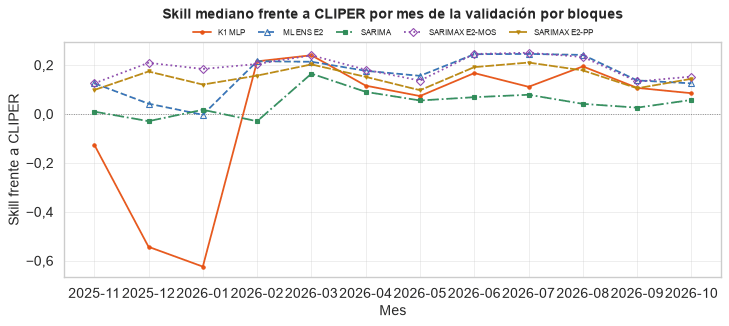

12 filas x 6 columnas; primeras 10:


modelo,K1 MLP,ML ENS E2,SARIMA,SARIMAX E2-MOS,SARIMAX E2-PP,ref: cliper
mes,,,,,,
2025-11,-0.1251,0.1257,0.0099,0.1257,0.0981,0.0
2025-12,-0.5429,0.0423,-0.0292,0.2095,0.1740,0.0
2026-01,-0.6238,-0.0029,0.0174,0.1843,0.1205,0.0
2026-02,0.2155,0.2157,-0.0294,0.2045,0.1571,0.0
2026-03,0.2403,0.2138,0.1652,0.2402,0.2029,0.0
2026-04,0.1161,0.1767,0.0907,0.1813,0.1520,0.0
2026-05,0.0736,0.1562,0.0554,0.1366,0.0974,0.0
2026-06,0.1674,0.2447,0.0689,0.2455,0.1918,0.0
2026-07,0.1113,0.2459,0.0788,0.2508,0.2106,0.0


**Skill mediano por temporada**

modelo,K1 MLP,ML ENS E2,SARIMA,SARIMAX E2-MOS,SARIMAX E2-PP,ref: cliper
temporada,,,,,,
resto del año,0.108,0.173,0.052,0.17,0.140,0.0
seca (diciembre a marzo),0.132,0.176,0.031,0.21,0.174,0.0


**Skill mediano por fase del ONI del mes**

modelo,K1 MLP,ML ENS E2,SARIMA,SARIMAX E2-MOS,SARIMAX E2-PP,ref: cliper
fase_oni,,,,,,
El Niño,0.134,0.194,0.043,0.193,0.142,0.0
La Niña,-0.221,0.114,0.001,0.140,0.099,0.0
neutro,0.163,0.181,0.084,0.205,0.162,0.0


In [7]:
SEL_M = ["ref: cliper", "SARIMA", "SARIMAX E2-MOS", "SARIMAX E2-PP", "ML ENS E2", "K1 MLP"]
skill_mes = MES[MES["modelo"].isin(SEL_M)].pivot_table(index="mes", columns="modelo", values="skill_vs_cliper", aggfunc="median")
nr_mes = MES[MES["modelo"].isin(SEL_M)].pivot_table(index="mes", columns="modelo", values="nrmse_pct", aggfunc="median")
unid_mes = MES[MES["modelo"] == "ref: cliper"].groupby("mes")["unidad"].nunique().rename("unidades")
display(Markdown("**Skill mediano frente a CLIPER por mes** (mediana entre unidades)")); display(skill_mes.round(3).join(unid_mes))
f = gr.lineas(skill_mes.drop(columns=["ref: cliper"], errors="ignore"), "Skill mediano frente a CLIPER por mes de la validación por bloques",
              "Mes", "Skill frente a CLIPER")
f.axes[0].axhline(0, color="grey", lw=0.8, ls=":")
fig(f, "skill_por_mes", skill_mes)
try:
    from tfm import datos
    oni_ = datos.oni()
    ONI_MES = pd.Series(oni_["oni"].to_numpy(), index=[f"{a}-{m:02d}" for a, m in zip(oni_["anio"], oni_["mes"])])
except Exception:  # noqa: BLE001
    ONI_MES = pd.Series(dtype=float)
MES["temporada"] = np.where(MES["mes"].str[-2:].astype(int).isin([12, 1, 2, 3]), "seca (diciembre a marzo)", "resto del año")
MES["fase_oni"] = pd.cut(MES["mes"].map(ONI_MES), [-np.inf, -0.5, 0.5, np.inf], labels=["La Niña", "neutro", "El Niño"]).astype(str)
POR_TEMP = MES[MES["modelo"].isin(SEL_M)].pivot_table(index="temporada", columns="modelo", values="skill_vs_cliper", aggfunc="median")
POR_FASE = MES[MES["modelo"].isin(SEL_M)].pivot_table(index="fase_oni", columns="modelo", values="skill_vs_cliper", aggfunc="median")
display(Markdown("**Skill mediano por temporada**")); display(POR_TEMP.round(3))
display(Markdown("**Skill mediano por fase del ONI del mes**")); display(POR_FASE.round(3))

### B.3 Modelo global en los mismos bloques

El cuaderno global reajusta su bosque aleatorio y su ensamble en las mismas fechas y deja sus predicciones por
unidad en `resultados/intermedios/bloques_global/`. Aquí se comparan con el modelo individual elegido con los bloques
y con CLIPER, en las horas comunes.

In [8]:
DIR_G = config.DIR_INTERMEDIOS / f"bloques_global{SUF}"
filas_g = []
for p in sorted(DIR_G.glob("*.parquet")) if DIR_G.exists() else []:
    u = p.stem
    clave = next((k for k in PRED if k.endswith("_" + u)), None)
    if clave is None:
        continue
    G = pd.read_parquet(p)
    D = PRED[clave]
    el = UNIDADES_B.loc[clave, "elegido_bloques"] if clave in UNIDADES_B.index and "elegido_bloques" in UNIDADES_B else None
    if not isinstance(el, str) or el not in D:
        continue
    for nombre_p, (ini, fin) in (("desarrollo", DESARROLLO), ("prueba", PRUEBA)):
        Dp = periodo(D, ini, fin)
        gp = G["global"].reindex(Dp.index)
        ok = Dp["observado"].astype(bool) & gp.notna() & Dp[[el, "ref: cliper"]].notna().all(axis=1)
        if ok.sum() < 48:
            continue
        dm = met.diebold_mariano_diario(Dp.loc[ok, "y"], gp[ok], Dp.loc[ok, el])
        eg, ei, ec = (met.evaluar(Dp.loc[ok, "y"], s[ok]) for s in (gp, Dp[el], Dp["ref: cliper"]))
        filas_g.append({"unidad": clave, "periodo": nombre_p, "individual": el, "nrmse_global": eg["nrmse_pct"],
                        "nrmse_individual": ei["nrmse_pct"], "skill_global_vs_cliper": 1 - eg["rmse"] / ec["rmse"],
                        "dm_global_vs_individual": dm["dm"], "p": dm["p_valor"]})
GLOBAL_B = pd.DataFrame(filas_g)
if not GLOBAL_B.empty:
    for nombre_p, g in GLOBAL_B.groupby("periodo"):
        p_h = multipletests(g["p"].fillna(1), method="holm")[1]
        GLOBAL_B.loc[g.index, "p_holm"] = p_h
    GLOBAL_B["veredicto"] = np.where(GLOBAL_B["p_holm"] >= 0.05, "sin diferencia significativa",
                                     np.where(GLOBAL_B["dm_global_vs_individual"] < 0, "global mejor", "individual mejor"))
    display(GLOBAL_B.round(3))
    display(GLOBAL_B.groupby(["periodo", "veredicto"]).size().unstack(fill_value=0))
else:
    display(Markdown("Sin predicciones del modelo global por bloques todavía (se generan en `04_global.ipynb`)."))

,unidad,periodo,individual,nrmse_global,nrmse_individual,skill_global_vs_cliper,dm_global_vs_individual,p,p_holm,veredicto
0,G01_P01I0102,desarrollo,SARIMAX E2-MOS,21.772,20.263,0.130,4.784,0.000,0.000,individual mejor
1,G01_P01I0102,prueba,SARIMAX E2-MOS,29.793,29.426,0.143,0.510,0.612,1.000,sin diferencia significativa
2,G01_P01I0202,desarrollo,SARIMAX E2-MOS,22.601,22.836,0.174,-0.568,0.570,1.000,sin diferencia significativa
3,G01_P01I0202,prueba,SARIMAX E2-MOS,30.278,29.564,0.110,0.887,0.379,1.000,sin diferencia significativa
4,G03_P02I0102,desarrollo,SARIMAX E2-MOS,23.900,23.666,0.227,0.680,0.497,1.000,sin diferencia significativa
5,G03_P02I0102,prueba,SARIMAX E2-MOS,36.075,36.642,0.145,-0.773,0.443,1.000,sin diferencia significativa
6,G03_P02I0202,desarrollo,SARIMAX E2-MOS,22.813,23.134,0.266,-0.975,0.330,1.000,sin diferencia significativa
7,G03_P02I0202,prueba,SARIMAX E2-MOS,36.153,36.118,0.150,0.047,0.962,1.000,sin diferencia significativa
8,G02_P04I0102,desarrollo,SARIMAX E2-PP,26.312,26.051,0.196,0.758,0.449,1.000,sin diferencia significativa
9,G02_P04I0102,prueba,SARIMAX E2-PP,29.936,30.816,0.073,-1.057,0.295,1.000,sin diferencia significativa


veredicto,global mejor,individual mejor,sin diferencia significativa
periodo,,,
desarrollo,0,1,13
prueba,3,0,10


## C. Conclusiones de la validación por bloques

In [9]:
acuerdo = UNIDADES_B.dropna(subset=["elegido_bloques"]) if "elegido_bloques" in UNIDADES_B else pd.DataFrame()
coinciden = int((acuerdo["elegido_bloques"] == acuerdo["seleccion_validacion"]).sum()) if len(acuerdo) else 0
conteo = acuerdo["elegido_bloques"].value_counts() if len(acuerdo) else pd.Series(dtype=int)
lineas = [f"- Unidades con bloques de desarrollo suficientes: {len(acuerdo)}; la elección por bloques coincide con la de la "
          f"validación en {coinciden}.",
          "- Modelo elegido por bloques: " + ", ".join(f"{k} en {v}" for k, v in conteo.items()) + "."]
if "skill_prueba" in UNIDADES_B:
    lineas.append(f"- Skill mediano del modelo elegido frente a CLIPER: prueba {100 * UNIDADES_B['skill_prueba'].median():.1f} %"
                  + (f", en vivo (después del corte) {100 * UNIDADES_B['skill_vivo'].median():.1f} %" if "skill_vivo" in UNIDADES_B else "") + ".")
for nombre, r_ in RESUMEN_H.iterrows():
    lineas.append(f"- {nombre}: el primero es mejor con significancia en {int(r_['a_mejor_significativo'])} de {int(r_['unidades'])} "
                  f"unidades, el segundo en {int(r_['b_mejor_significativo'])} y no difieren en {int(r_['sin_diferencia'])}.")
display(Markdown("\n".join(lineas)))
res.registrar("bloques", {
    "unidades": UNIDADES_B.drop(columns=["en_mcs"], errors="ignore").round(4).replace({np.nan: None}).to_dict(orient="index"),
    "mcs_desarrollo": UNIDADES_B["en_mcs"].dropna().to_dict() if "en_mcs" in UNIDADES_B else {},
    "conteo_elegido": conteo.to_dict(), "coincide_con_validacion": coinciden, "con_desarrollo": len(acuerdo),
    "hipotesis": RESUMEN_H.round(4).to_dict(orient="index"),
    "skill_por_mes": skill_mes.round(4).to_dict(orient="index"), "skill_por_temporada": POR_TEMP.round(4).to_dict(orient="index"),
    "skill_por_fase_oni": POR_FASE.round(4).to_dict(orient="index"),
    "global": GLOBAL_B.round(4).to_dict(orient="records") if not GLOBAL_B.empty else [],
    "conclusiones": lineas})
tiempos.reporte()

- Unidades con bloques de desarrollo suficientes: 17; la elección por bloques coincide con la de la validación en 8.
- Modelo elegido por bloques: SARIMAX E2-MOS en 11, SARIMA en 3, ref: cliper en 2, SARIMAX E2-PP en 1.
- Skill mediano del modelo elegido frente a CLIPER: prueba 9,8 %.
- PI1 SARIMA frente a CLIPER: el primero es mejor con significancia en 9 de 17 unidades, el segundo en 0 y no difieren en 8.
- PI1 SARIMAX E2-MOS frente a CLIPER: el primero es mejor con significancia en 17 de 17 unidades, el segundo en 0 y no difieren en 0.
- PI3 SARIMAX E2-MOS frente a E2-PP: el primero es mejor con significancia en 7 de 17 unidades, el segundo en 1 y no difieren en 9.
- PI6 MLP frente a SARIMAX E2-MOS: el primero es mejor con significancia en 1 de 17 unidades, el segundo en 15 y no difieren en 1.
- PI6 ensamble frente a SARIMAX E2-MOS: el primero es mejor con significancia en 2 de 17 unidades, el segundo en 4 y no difieren en 11.

**Tiempo total: 230.7 min** en 5 celdas; memoria libre mínima 3.4 GB; memoria máxima del proceso 0.5 GB.

,celdas,segundos,memoria_proceso_max_gb,memoria_libre_min_gb,minutos,porcentaje
seccion,,,,,,
,5,13844.02,0.5,3.4,230.73,100.0


**Las 15 celdas más lentas**

,n,seccion,primera_linea,segundos,memoria_proceso_gb,memoria_libre_gb,error,fin
0,1,,"def postproceso(p, yr_cs):",13838.09,0.46,3.43,False,2026-11-08 16:33:52
1,2,,"ARCHIVOS = sorted(DIR_PRED_B.glob(""*.parquet""))",2.64,0.48,3.42,False,2026-11-08 16:33:55
2,3,,"PARES = {""PI1 SARIMA frente a CLIPER"": (""SARIM...",1.35,0.48,3.42,False,2026-11-08 16:33:56
3,4,,"SEL_M = [""ref: cliper"", ""SARIMA"", ""SARIMAX E2-...",1.31,0.49,3.40,False,2026-11-08 16:33:57
4,5,,"DIR_G = config.DIR_INTERMEDIOS / f""bloques_glo...",0.63,0.50,3.40,False,2026-11-08 16:33:58


,celdas,segundos,memoria_proceso_max_gb,memoria_libre_min_gb,minutos,porcentaje
seccion,,,,,,
,5,13844.02,0.5,3.4,230.73,100.0
